<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/09_third_variable_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/09_third_variable_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 5: do notebook 02's decade patterns hold within wargames and within other games?

*AI-assisted: every code and markdown cell was generated with Claude (Opus 5.5) on 2026-11-09 and reviewed, run and edited by Andrew Reicin. None of this text is for the slides or report.*

Wargames fell from about half of 1970s games to about a tenth of 2020s games. This notebook redraws notebook 02's decade patterns separately for wargames and for all other games, to see which patterns hold within each group and which come from the change in mix.

- **Wargame:** any game that lists Wargame among its categories (same counting rule as notebook 02). The games with no category listed are left out.
- **Patterns:** play time, player counts, minimum age, and mechanics.
- **Charts:** lines comparing the groups, plus boxplots where the spread matters. Every chart's numbers are printed under it.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 5, notebook 02's decade patterns within wargames and within other games ---
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Every code and markdown cell in this notebook was generated with Claude and reviewed, run and edited by Andrew Reicin.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."
def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

COLORS = {"Wargames": "tab:red", "Other games": "tab:blue", "All games": "0.5"}

## 1. Load, scope and groups

Same data and decades as notebook 02 (1970s to 2020s).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Load the data and keep the same decades as notebook 02; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

dec = games[games["decade"] >= 1970].copy()
dec["decade"] = dec["decade"].astype(int).astype(str) + "s"
print("games 1970s to 2020s:", len(dec))

games 1970s to 2020s: 20983


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Split into wargames and other games; reviewed and edited by Andrew Reicin.
# A game is a wargame if 'Wargame' is one of its listed categories. Games with no category listed are left out.
print("games with no category listed (left out):", dec["boardgamecategory"].isna().sum())
dec = dec[dec["boardgamecategory"].notna()].copy()
dec["group"] = np.where(dec["boardgamecategory"].str.contains("Wargame"), "Wargames", "Other games")

group_counts = dec.groupby(["decade", "group"]).size().unstack()
group_counts["% wargames"] = (group_counts["Wargames"] / group_counts.sum(axis=1) * 100).round(1)
group_counts

games with no category listed (left out): 275


group,Other games,Wargames,% wargames
decade,,,
1970s,382,406,51.5
1980s,772,541,41.2
1990s,1408,634,31.0
2000s,3793,825,17.9
2010s,9117,1204,11.7
2020s,1467,159,9.8


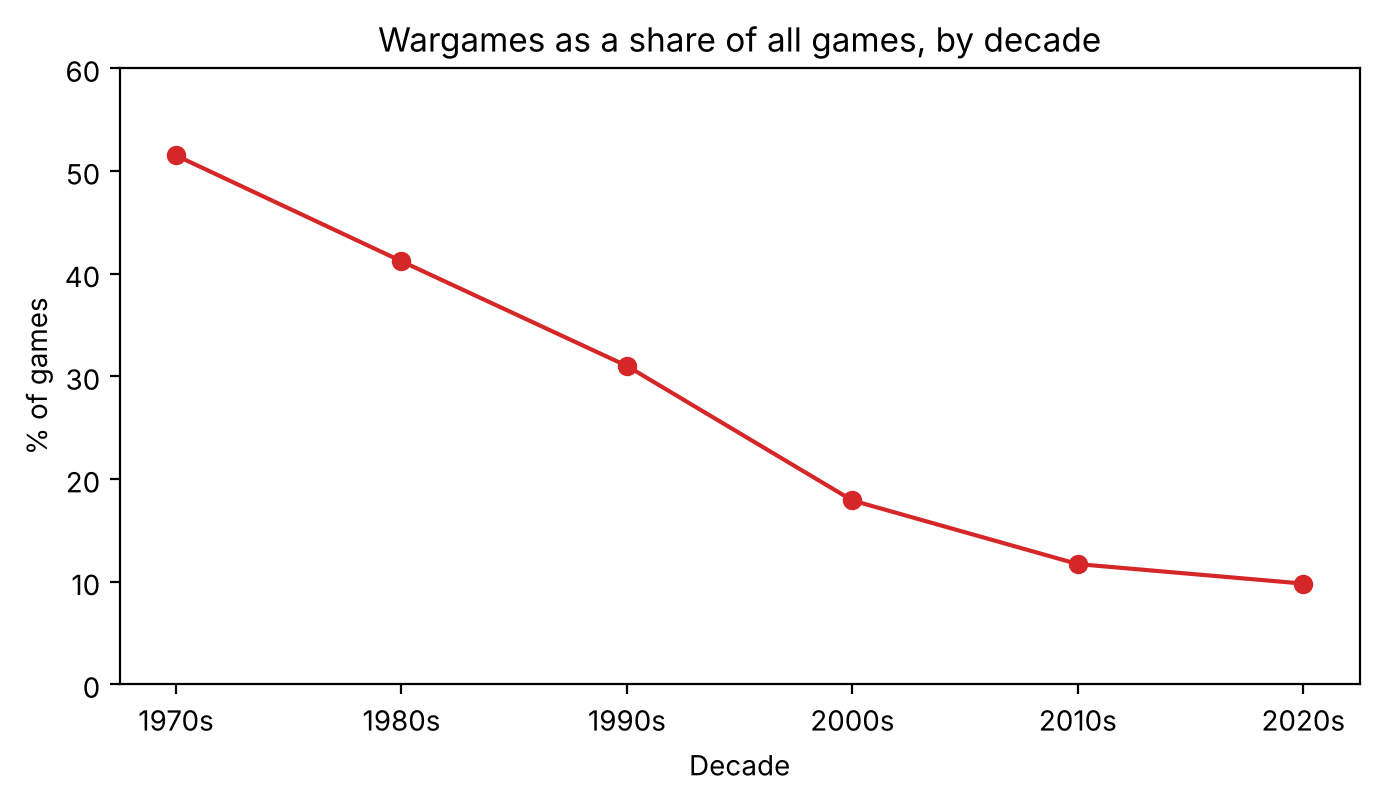

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: the share of wargames by decade; reviewed and edited by Andrew Reicin.
ax = group_counts["% wargames"].plot(marker="o", color=COLORS["Wargames"], figsize=(8, 4))
ax.set_title("Wargames as a share of all games, by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("% of games")
ax.set_ylim(0, 60)
save("09_wargame_share_by_decade.png")
plt.show()

Wargames fall from 51.5% of games in the 1970s to 9.8% in the 2020s, with at least 159 wargames in every decade.

## 2. Helper for the line charts

Each line chart shows one measure by decade for wargames, other games, and all games together (dashed, the line notebook 02 shows).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. A function that draws one measure for the two groups and for all games; reviewed and edited by Andrew Reicin.
def lines_by_group(table_by_group, table_all, ax, title, ylabel):
    for grp in ["Wargames", "Other games"]:
        ax.plot(table_by_group.index, table_by_group[grp], marker="o", color=COLORS[grp], label=grp)
    ax.plot(table_all.index, table_all, marker="o", linestyle="--", color=COLORS["All games"], label="All games (notebook 02)")
    ax.set_title(title)
    ax.set_xlabel("Decade")
    ax.set_ylabel(ylabel)

## 3. Play time

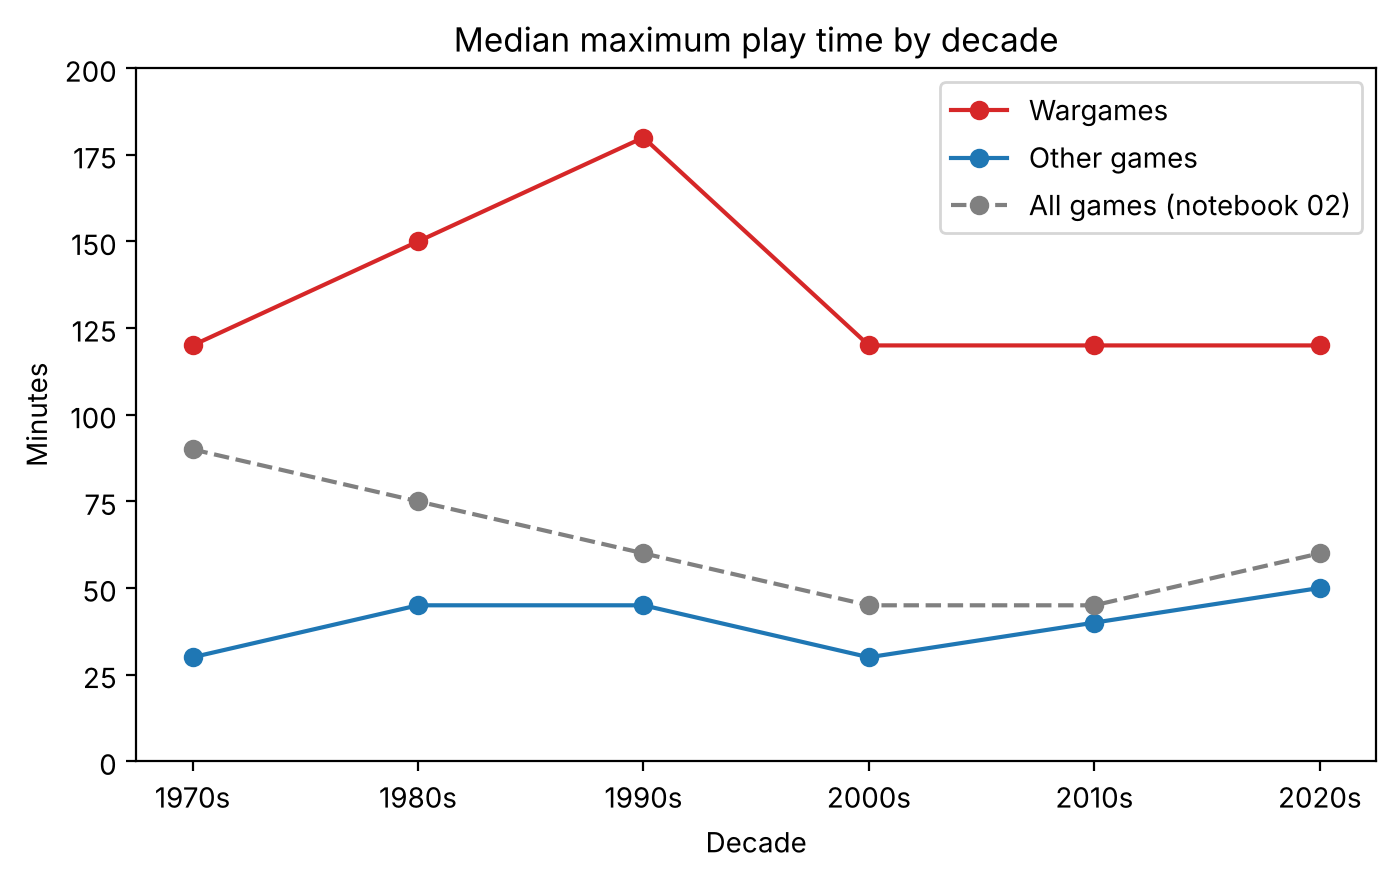

,Other games,Wargames,All games,games: Other games,games: Wargames
decade,,,,,
1970s,30.0,120.0,90.0,373,398
1980s,45.0,150.0,75.0,753,527
1990s,45.0,180.0,60.0,1385,589
2000s,30.0,120.0,45.0,3676,796
2010s,40.0,120.0,45.0,8809,1113
2020s,50.0,120.0,60.0,1436,146


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Median maximum play time by decade, by group; reviewed and edited by Andrew Reicin.
pt = dec.dropna(subset=["maxplaytime"])
pt_group = pt.groupby(["decade", "group"])["maxplaytime"].median().unstack()
pt_all = pt.groupby("decade")["maxplaytime"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
lines_by_group(pt_group, pt_all, ax, "Median maximum play time by decade", "Minutes")
ax.set_ylim(0, 200)
ax.legend()
save("09_playtime_lines.png")
plt.show()

pd.concat([pt_group, pt_all.rename("All games"), pt.groupby(["decade", "group"]).size().unstack().add_prefix("games: ")], axis=1)

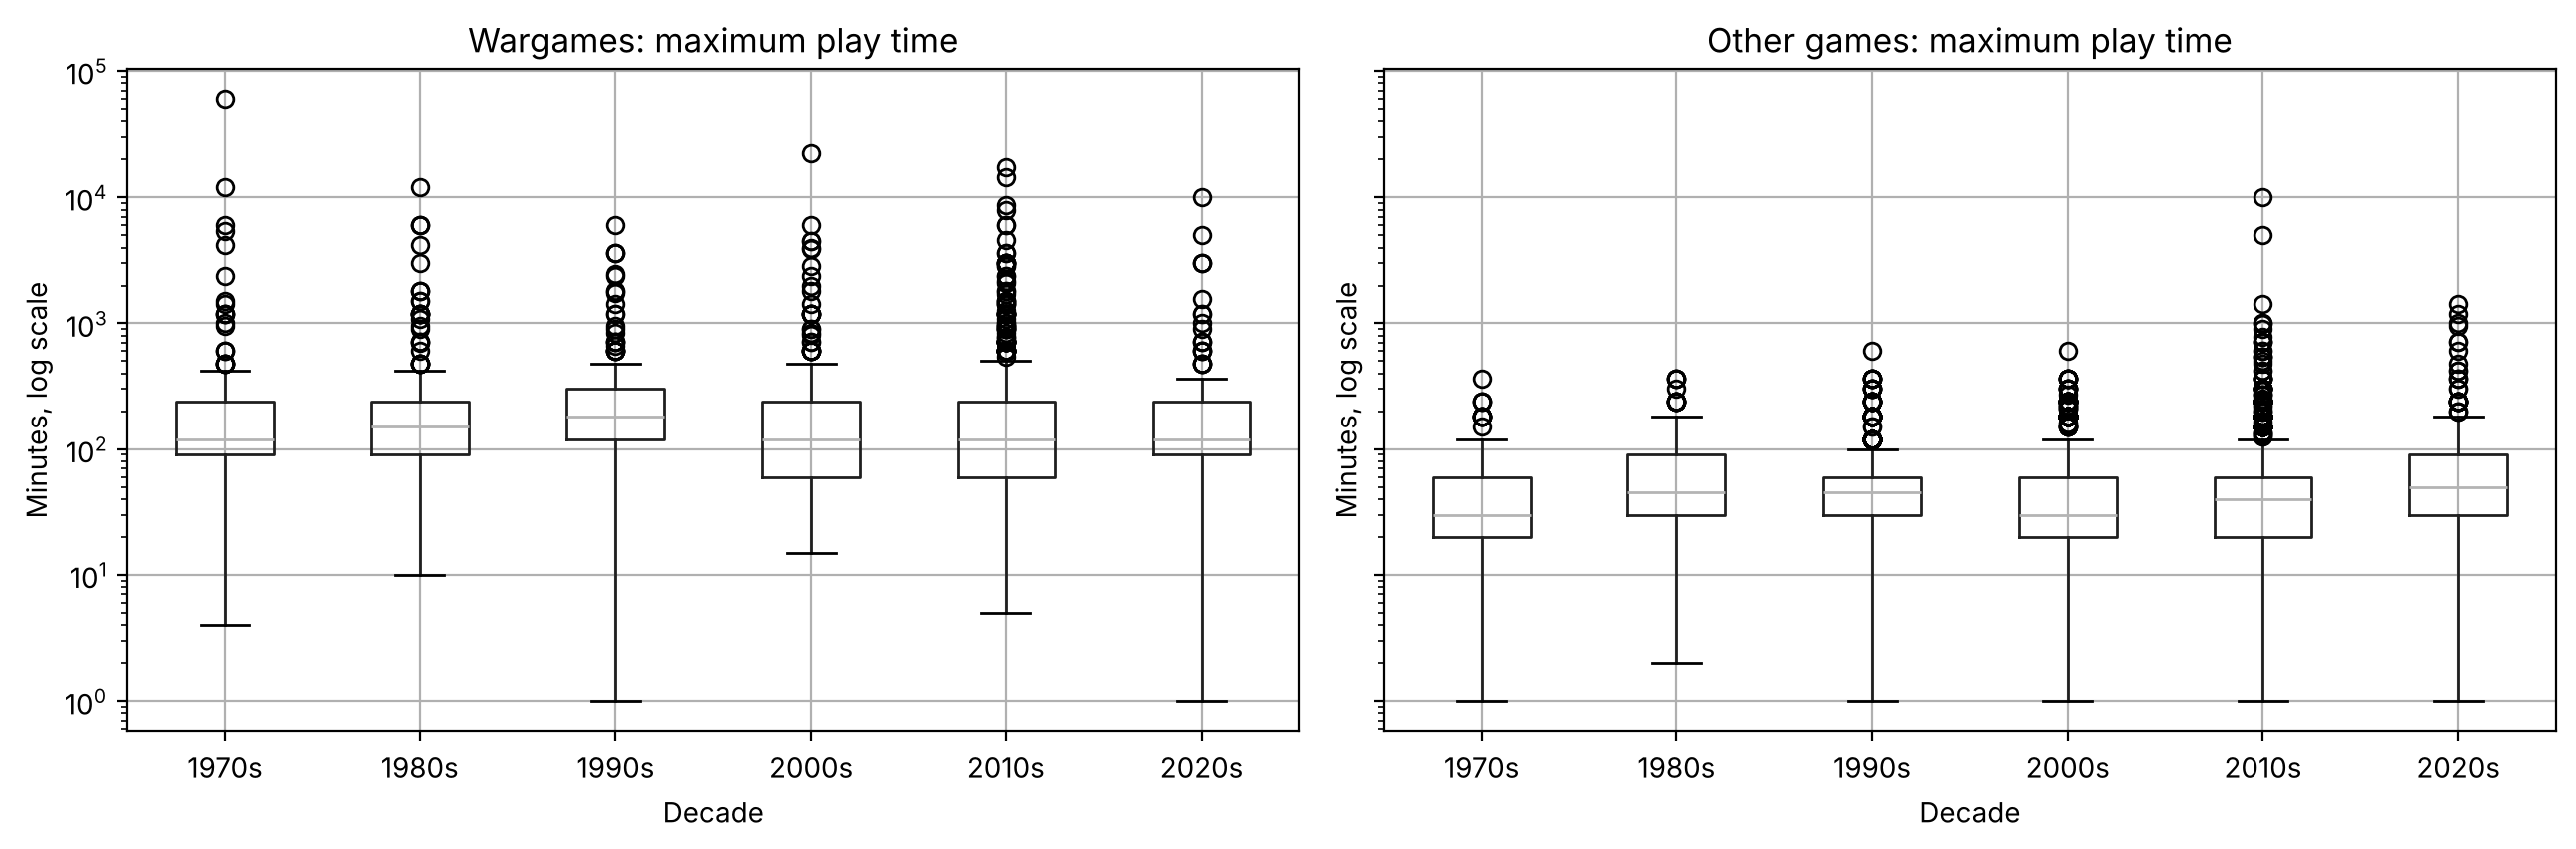

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Full spread of play time, one panel per group; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, grp in zip(axes, ["Wargames", "Other games"]):
    pt[pt["group"] == grp].boxplot(column="maxplaytime", by="decade", ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"{grp}: maximum play time")
    ax.set_xlabel("Decade")
    ax.set_ylabel("Minutes, log scale")
plt.suptitle("")
plt.tight_layout()
save("09_playtime_boxplots.png")
plt.show()

- **Wargames:** median 120 min in the 1970s, up to 150 (1980s) and 180 (1990s), back to 120 from the 2000s on.
- **Other games:** 30 min in the 1970s, 45 in the 1980s and 1990s, a dip to 30 in the 2000s, then 40 and 50.
- **All games** fall from 90 to 45 and back to 60 mainly because long wargames become a smaller share.
- **Verdict: reverses.**

## 4. Player counts

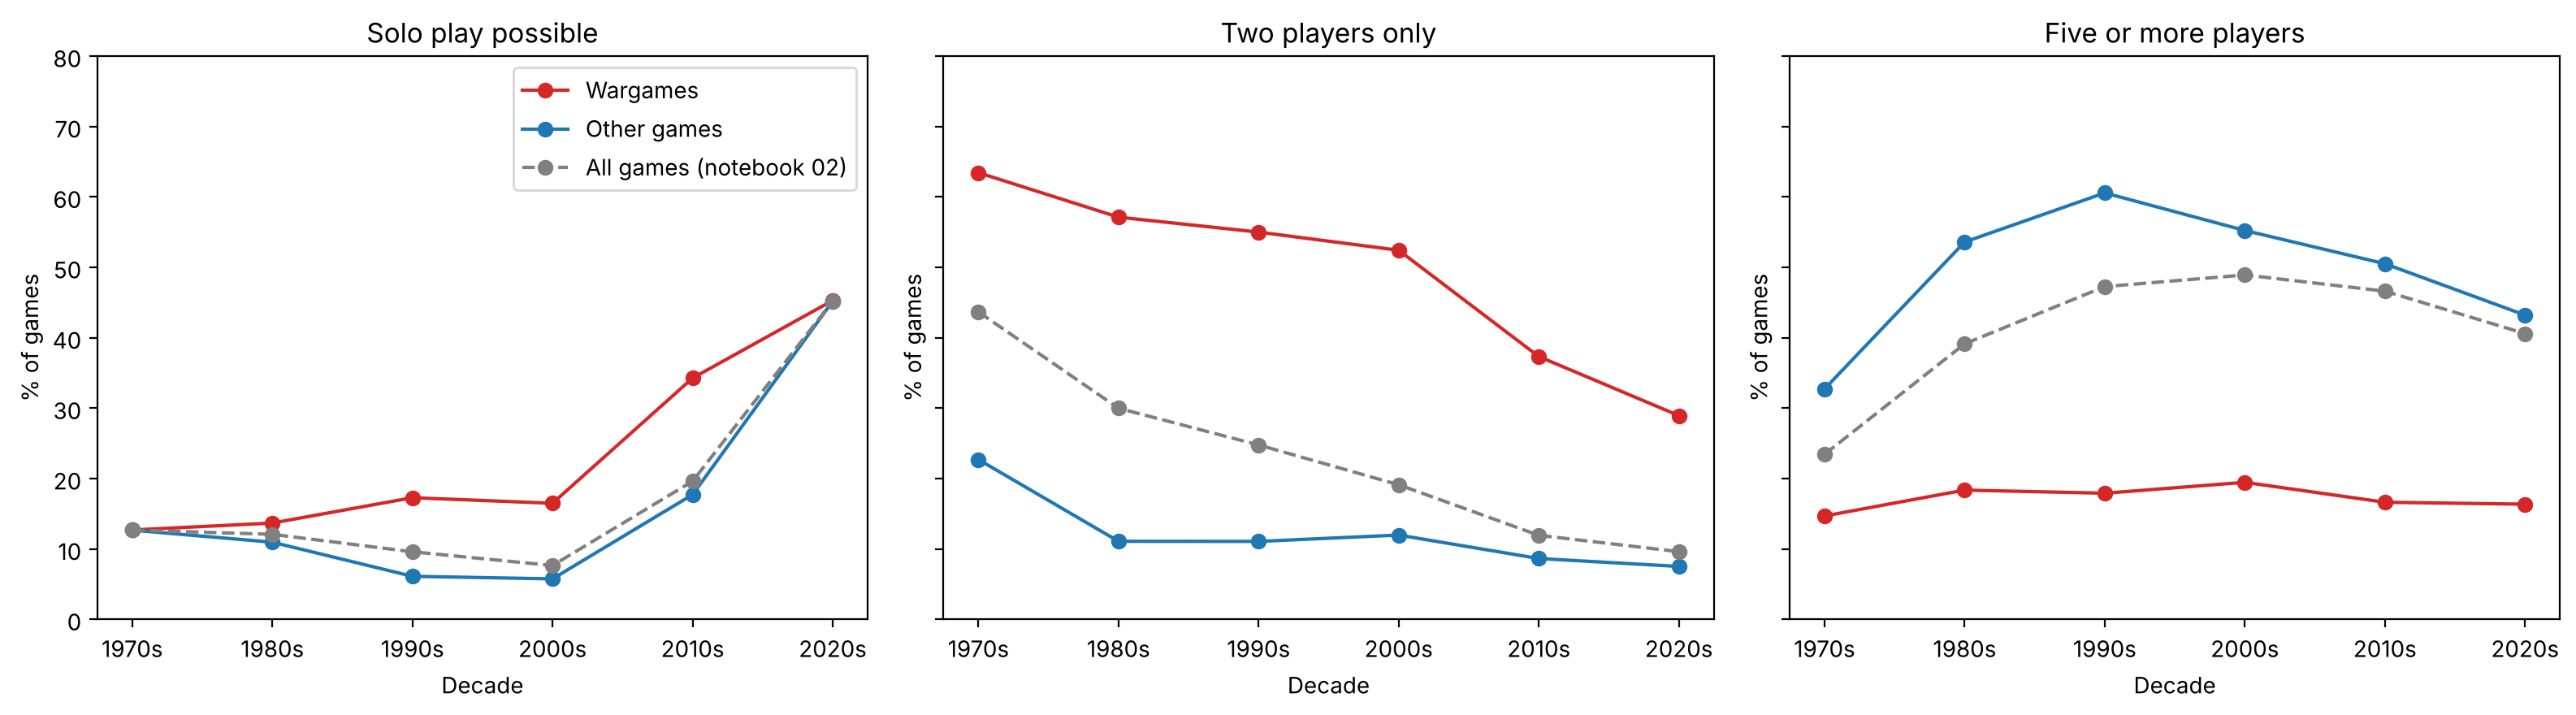

Solo play possible                    Two players only           \
              Other games Wargames All games      Other games Wargames   
decade                                                                   
1970s                12.7     12.7      12.7             22.7     63.4   
1980s                11.0     13.7      12.1             11.1     57.1   
1990s                 6.1     17.3       9.6             11.1     55.0   
2000s                 5.7     16.5       7.6             12.0     52.4   
2010s                17.7     34.3      19.6              8.6     37.3   
2020s                45.2     45.3      45.2              7.5     28.9   

                 Five or more players                     
       All games          Other games Wargames All games  
decade                                                    
1970s       43.7                 32.7     14.7      23.4  
1980s       30.0                 53.6     18.4      39.1  
1990s       24.8                 60.6     17.9      47.3  
2000s       19.1                 55.2     19.5      48.9  
2010s       11.9                 50.5     16.6      46.6  
2020s        9.6                 43.2     16.4      40.6

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Solo, two-player-only and five-or-more shares by decade, by group; reviewed and edited by Andrew Reicin.
pc = dec.dropna(subset=["minplayers", "maxplayers"]).copy()
pc["Solo play possible"] = pc["minplayers"] == 1
pc["Two players only"] = (pc["minplayers"] == 2) & (pc["maxplayers"] == 2)
pc["Five or more players"] = pc["maxplayers"] >= 5
measures = ["Solo play possible", "Two players only", "Five or more players"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
pc_tables = {}
for ax, m in zip(axes, measures):
    by_group = pc.groupby(["decade", "group"])[m].mean().unstack() * 100
    by_all = pc.groupby("decade")[m].mean() * 100
    lines_by_group(by_group, by_all, ax, m, "% of games")
    pc_tables[m] = pd.concat([by_group, by_all.rename("All games")], axis=1)
axes[0].legend()
axes[0].set_ylim(0, 80)
plt.tight_layout()
save("09_player_counts_lines.png")
plt.show()

pd.concat(pc_tables, axis=1).round(1)

- **Solo play:** other games fall from 13% to 6% (1990s-2000s), wargames rise steadily from 13% to 17%; both then climb to 45% by the 2020s. **Holds.**
- **Two players only:** other games fall from 23% to 11% by the 1980s and stay around 8-12%; wargames fall steadily from 63% to 29%. **Holds.**
- **Five or more players:** other games rise from 33% to 61% (1990s) then ease to 43%; wargames stay around 15-20%. The all-games rise is **mostly the mix**.

## 5. Minimum age

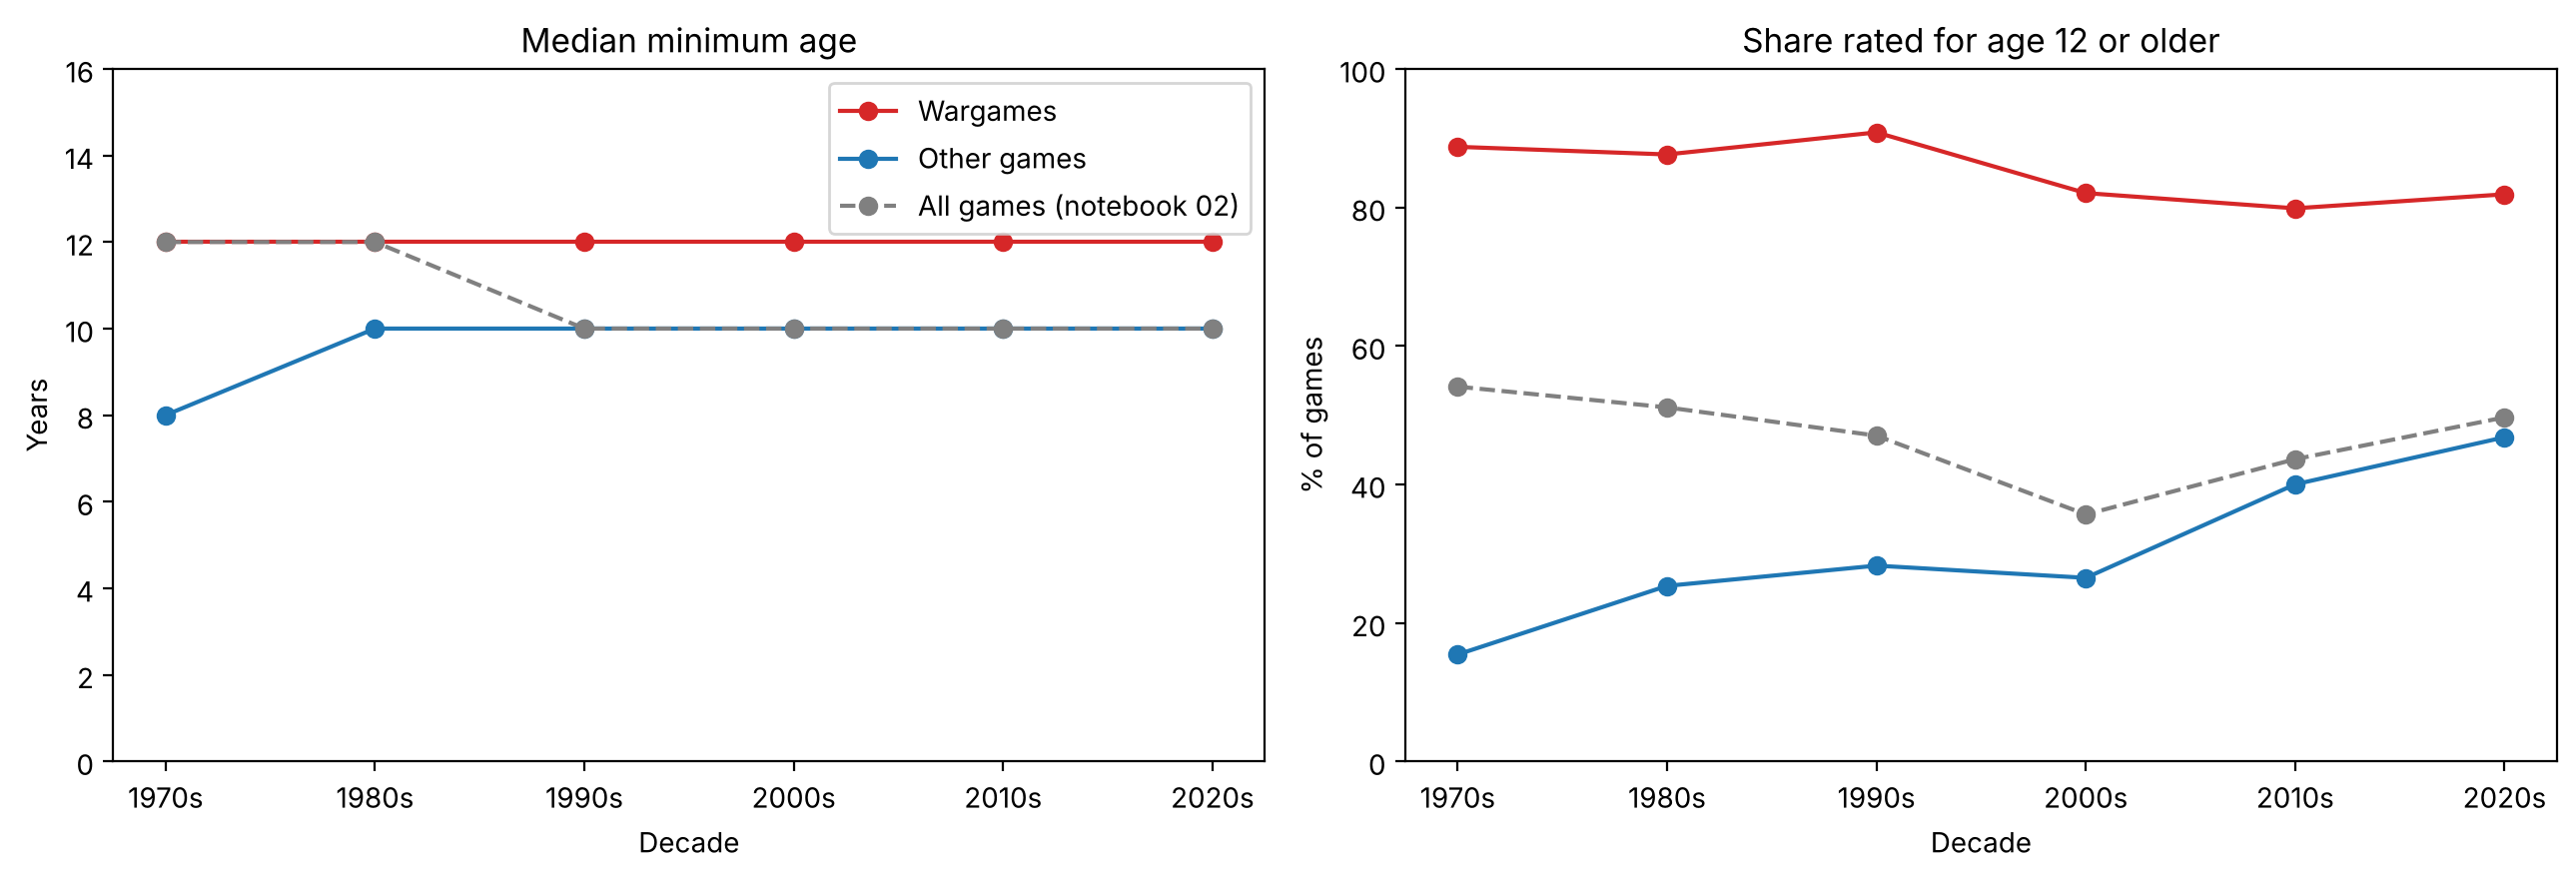

median age            % age 12+                games         
group  Other games Wargames Other games Wargames Other games Wargames
decade                                                               
1970s          8.0     12.0        15.4     88.7         350      391
1980s         10.0     12.0        25.3     87.6         734      518
1990s         10.0     12.0        28.3     90.8        1348      578
2000s         10.0     12.0        26.5     82.1        3532      697
2010s         10.0     12.0        40.0     79.9        8914      894
2020s         10.0     12.0        46.8     81.9        1425      127

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Median minimum age and the share rated 12 or older, by group; reviewed and edited by Andrew Reicin.
ma = dec.dropna(subset=["minage"]).copy()
ma["Age 12 or older"] = ma["minage"] >= 12

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
lines_by_group(ma.groupby(["decade", "group"])["minage"].median().unstack(), ma.groupby("decade")["minage"].median(),
               axes[0], "Median minimum age", "Years")
axes[0].set_ylim(0, 16)
lines_by_group(ma.groupby(["decade", "group"])["Age 12 or older"].mean().unstack() * 100, ma.groupby("decade")["Age 12 or older"].mean() * 100,
               axes[1], "Share rated for age 12 or older", "% of games")
axes[1].set_ylim(0, 100)
axes[0].legend()
plt.tight_layout()
save("09_min_age_lines.png")
plt.show()

pd.concat({"median age": ma.groupby(["decade", "group"])["minage"].median().unstack(),
           "% age 12+": (ma.groupby(["decade", "group"])["Age 12 or older"].mean().unstack() * 100).round(1),
           "games": ma.groupby(["decade", "group"]).size().unstack()}, axis=1)

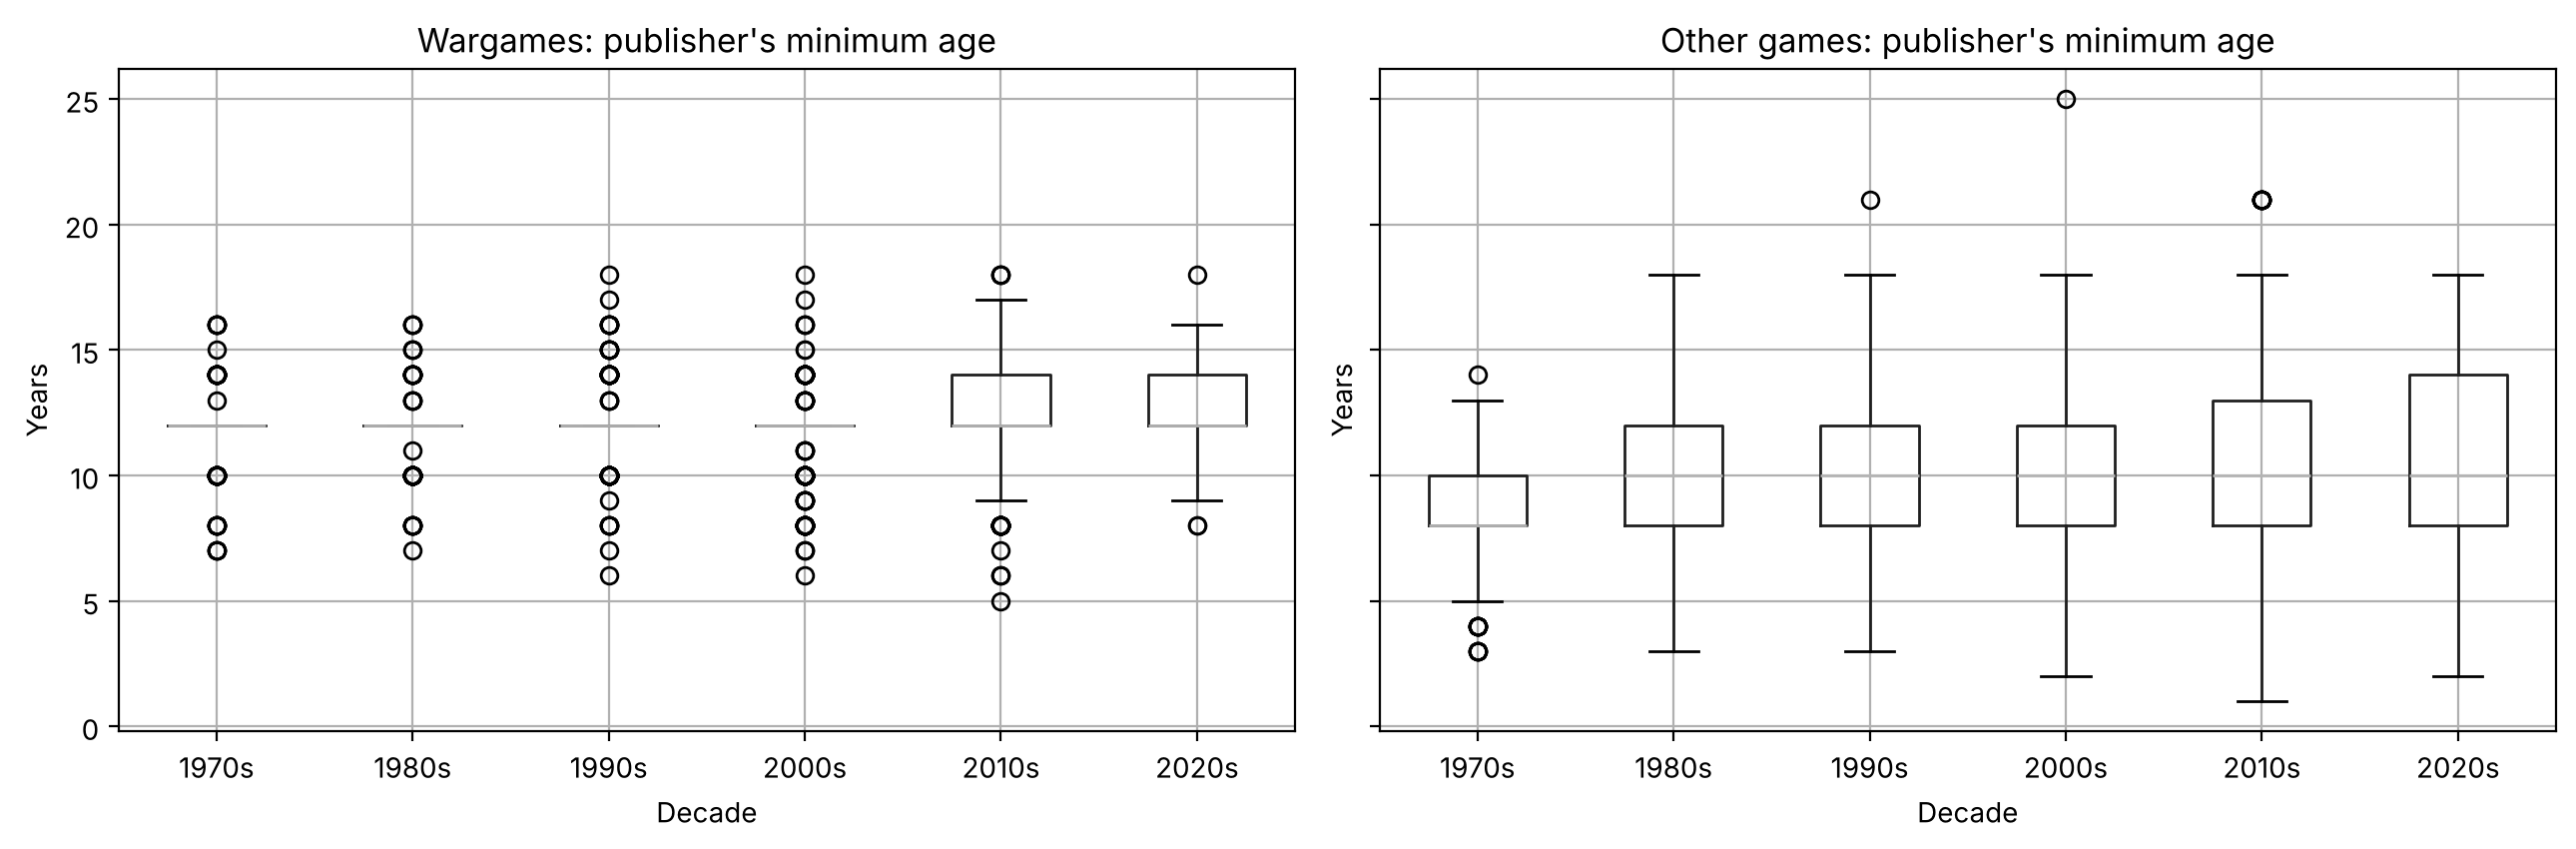

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Full spread of minimum age, one panel per group; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, grp in zip(axes, ["Wargames", "Other games"]):
    ma[ma["group"] == grp].boxplot(column="minage", by="decade", ax=ax)
    ax.set_title(f"{grp}: publisher's minimum age")
    ax.set_xlabel("Decade")
    ax.set_ylabel("Years")
plt.suptitle("")
plt.tight_layout()
save("09_min_age_boxplots.png")
plt.show()

- **Wargames:** median 12 in every decade; the share rated 12+ stays between 80% and 91%.
- **Other games:** median 8 in the 1970s, 10 from the 1980s on; the share rated 12+ climbs from 15% to 25-28% (1980s-2000s), 40% (2010s) and 47% (2020s).
- **Verdict: reverses.**

## 6. Mechanics

Games with at least one mechanic listed, as in notebook 02.

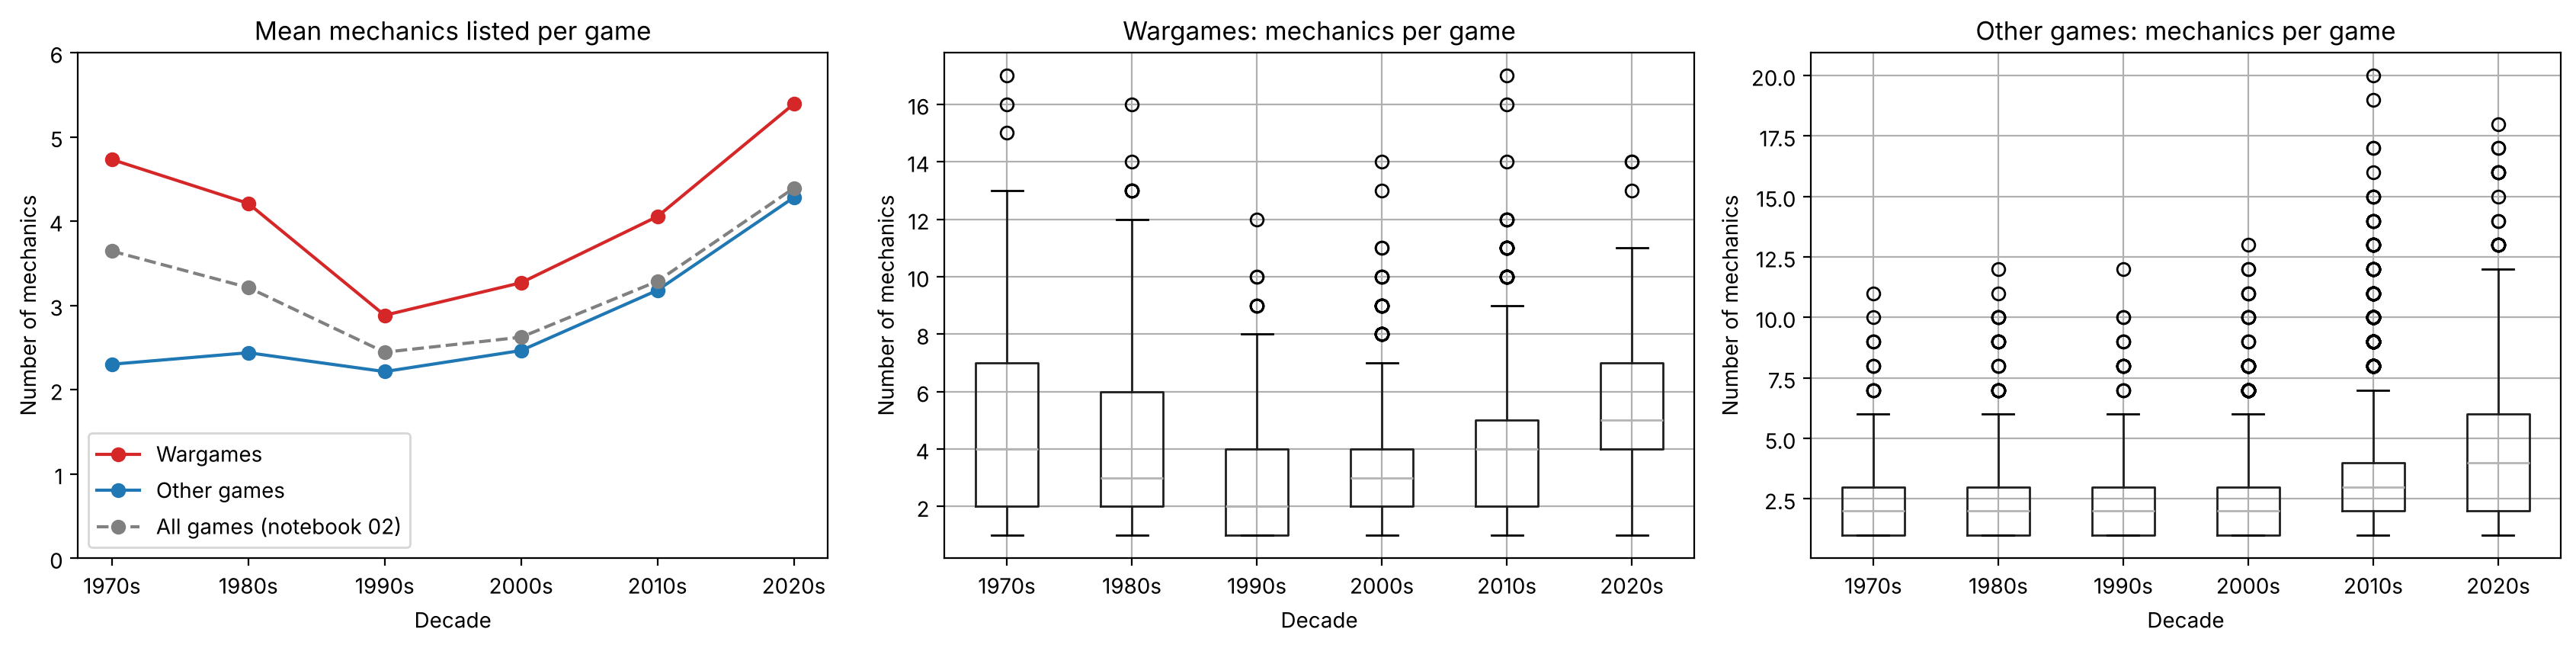

median                 mean                games         
group  Other games Wargames Other games Wargames Other games Wargames
decade                                                               
1970s          2.0      4.0        2.30     4.73         328      405
1980s          2.0      3.0        2.44     4.21         689      534
1990s          2.0      2.0        2.21     2.88        1184      622
2000s          2.0      3.0        2.46     3.27        3316      811
2010s          3.0      4.0        3.18     4.05        8582     1196
2020s          4.0      5.0        4.28     5.39        1435      159

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Mechanics listed per game, by group; reviewed and edited by Andrew Reicin.
mg = dec[dec["boardgamemechanic"].notna()].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
lines_by_group(mg.groupby(["decade", "group"])["n_mechanics"].mean().unstack(), mg.groupby("decade")["n_mechanics"].mean(),
               axes[0], "Mean mechanics listed per game", "Number of mechanics")
axes[0].set_ylim(0, 6)
axes[0].legend()
for ax, grp in zip(axes[1:], ["Wargames", "Other games"]):
    mg[mg["group"] == grp].boxplot(column="n_mechanics", by="decade", ax=ax)
    ax.set_title(f"{grp}: mechanics per game")
    ax.set_xlabel("Decade")
    ax.set_ylabel("Number of mechanics")
plt.suptitle("")
plt.tight_layout()
save("09_mechanics_per_game.png")
plt.show()

pd.concat({"median": mg.groupby(["decade", "group"])["n_mechanics"].median().unstack(),
           "mean": mg.groupby(["decade", "group"])["n_mechanics"].mean().unstack().round(2),
           "games": mg.groupby(["decade", "group"]).size().unstack()}, axis=1)

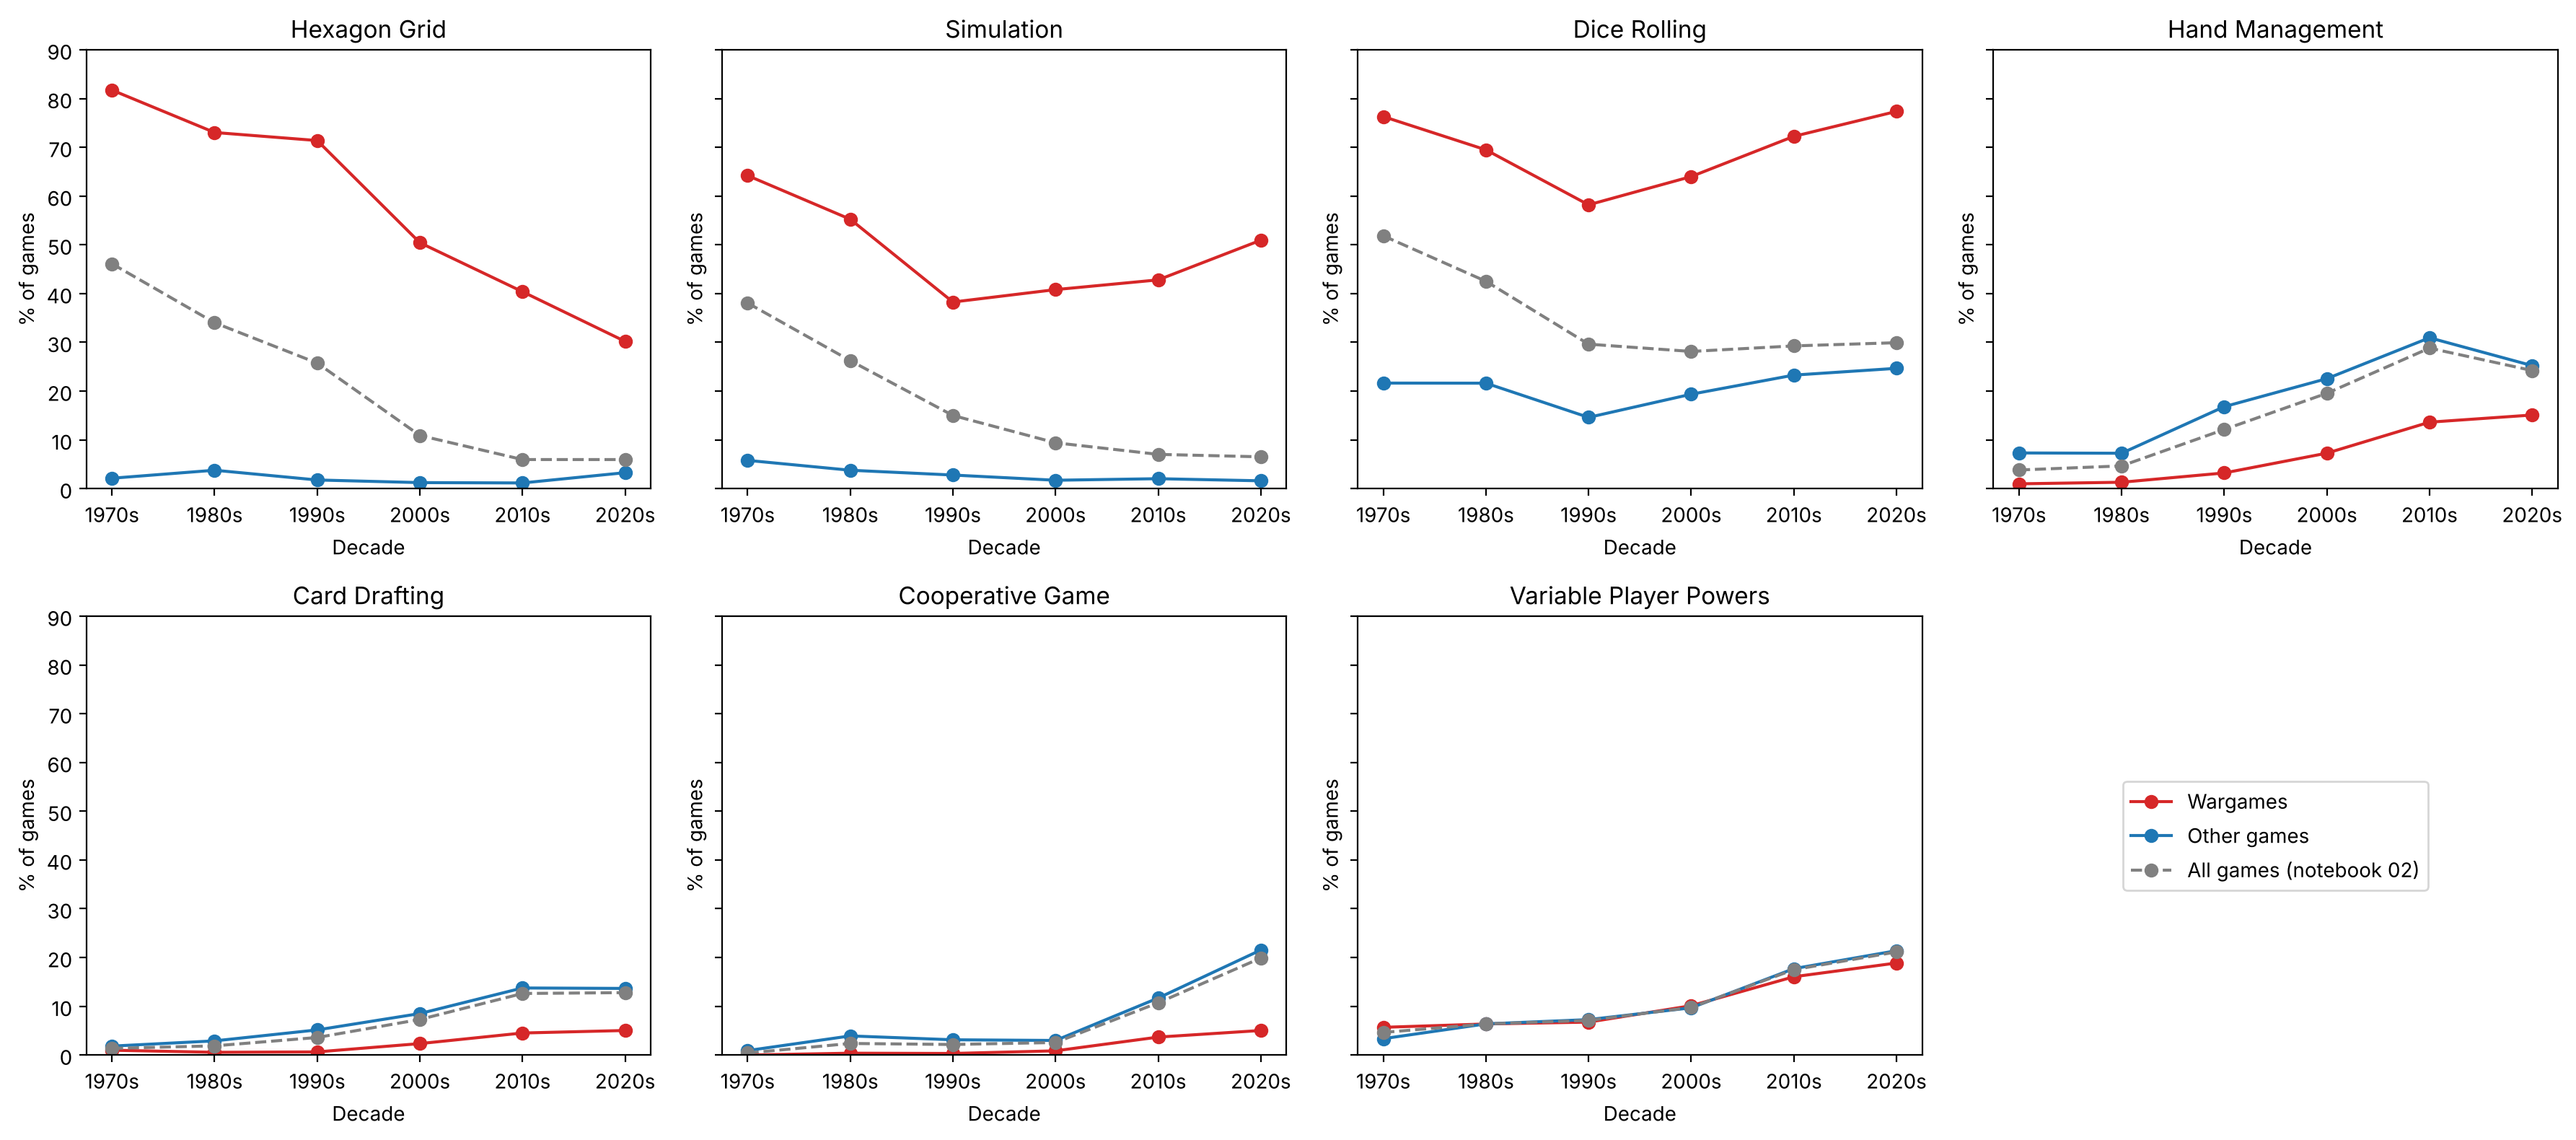

Hexagon Grid                     Simulation                     \
        Other games Wargames All games Other games Wargames All games   
decade                                                                  
1970s           2.1     81.7      46.1         5.8     64.2      38.1   
1980s           3.8     73.0      34.0         3.8     55.2      26.2   
1990s           1.8     71.4      25.7         2.8     38.3      15.0   
2000s           1.2     50.4      10.9         1.7     40.8       9.4   
2010s           1.2     40.4       6.0         2.0     42.8       7.0   
2020s           3.3     30.2       6.0         1.6     50.9       6.5   

       Dice Rolling                    Hand Management  ...            \
        Other games Wargames All games     Other games  ... All games   
decade                                                  ...             
1970s          21.6     76.3      51.8             7.3  ...       3.8   
1980s          21.6     69.5      42.5             7.3  ...       4.7   
1990s          14.6     58.2      29.6            16.8  ...      12.1   
2000s          19.4     64.0      28.1            22.6  ...      19.6   
2010s          23.3     72.2      29.3            30.9  ...      28.8   
2020s          24.7     77.4      29.9            25.2  ...      24.2   

       Card Drafting                    Cooperative Game                     \
         Other games Wargames All games      Other games Wargames All games   
decade                                                                        
1970s            1.8      1.0       1.4              0.9      0.0       0.4   
1980s            2.9      0.6       1.9              3.9      0.4       2.4   
1990s            5.2      0.6       3.6              3.1      0.3       2.2   
2000s            8.5      2.3       7.3              3.0      0.9       2.6   
2010s           13.7      4.5      12.6             11.7      3.7      10.7   
2020s           13.7      5.0      12.8             21.5      5.0      19.9   

       Variable Player Powers                     
                  Other games Wargames All games  
decade                                            
1970s                     3.4      5.7       4.6  
1980s                     6.4      6.4       6.4  
1990s                     7.3      6.8       7.1  
2000s                     9.7     10.1       9.8  
2010s                    17.7     16.1      17.5  
2020s                    21.4     18.9      21.1  

[6 rows x 21 columns]

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Share of games using each key mechanic, by group; reviewed and edited by Andrew Reicin.
key_mechanics = ["Hexagon Grid", "Simulation", "Dice Rolling", "Hand Management", "Card Drafting", "Cooperative Game", "Variable Player Powers"]
mech = mg["boardgamemechanic"].str.get_dummies(sep="|")[key_mechanics]
mech["decade"] = mg["decade"]
mech["group"] = mg["group"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
mech_tables = {}
for ax, m in zip(axes.flat, key_mechanics):
    by_group = mech.groupby(["decade", "group"])[m].mean().unstack() * 100
    by_all = mech.groupby("decade")[m].mean() * 100
    lines_by_group(by_group, by_all, ax, m, "% of games")
    mech_tables[m] = pd.concat([by_group, by_all.rename("All games")], axis=1)
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
axes.flat[0].set_ylim(0, 90)
plt.tight_layout()
save("09_key_mechanics_lines.png")
plt.show()

pd.concat(mech_tables, axis=1).round(1)

- **Mechanics per game:** other games stay around 2.2-2.5 through the 2000s; wargames dip from 4.7 to 2.9 (1990s). Both then rise to their highest in the 2020s (other games 4.3, wargames 5.4). **Holds, stronger within groups.**
- **Hexagon grid:** 1-4% of other games in every decade; wargames fall from 82% to 30%. **Mostly the mix, plus a real fall within wargames.**
- **Simulation:** other games 6% to 2%; wargames fall to 38% in the 1990s, then recover to 51%. **Mostly the mix.**
- **Dice rolling:** both groups dip in the 1990s (other 15%, wargames 58%) and return to their 1970s levels by the 2020s. **Entirely the mix.**
- **Hand management, card drafting, co-op, variable player powers:** rise in both groups, mostly from the 1990s (hand management) or 2010s (co-op, variable player powers) on. **Hold.**

## 7. All patterns side by side: 1970s vs 2020s

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Summary table: each pattern in the 1970s and 2020s, for all games and within each group; reviewed and edited by Andrew Reicin.
rows = []
def add(measure, by_group, by_all):
    rows.append({"pattern": measure,
                 "all games 1970s": by_all["1970s"], "all games 2020s": by_all["2020s"],
                 "other games 1970s": by_group.loc["1970s", "Other games"], "other games 2020s": by_group.loc["2020s", "Other games"],
                 "wargames 1970s": by_group.loc["1970s", "Wargames"], "wargames 2020s": by_group.loc["2020s", "Wargames"]})

add("Median max play time (min)", pt_group, pt_all)
for m in measures:
    add(f"% {m.lower()}", pc_tables[m][["Wargames", "Other games"]], pc_tables[m]["All games"])
add("Median minimum age", ma.groupby(["decade", "group"])["minage"].median().unstack(), ma.groupby("decade")["minage"].median())
add("% rated age 12+", ma.groupby(["decade", "group"])["Age 12 or older"].mean().unstack() * 100, ma.groupby("decade")["Age 12 or older"].mean() * 100)
add("Mean mechanics per game", mg.groupby(["decade", "group"])["n_mechanics"].mean().unstack(), mg.groupby("decade")["n_mechanics"].mean())
for m in key_mechanics:
    add(f"% {m}", mech_tables[m][["Wargames", "Other games"]], mech_tables[m]["All games"])

summary = pd.DataFrame(rows).set_index("pattern").round(1)

# Verdicts, decided by Andrew Reicin from the charts above (full decade path, not only the end points).
verdicts = {
    "Median max play time (min)": "Reverses: other games got longer; the overall fall is the wargame decline",
    "% solo play possible": "Holds in both groups",
    "% two players only": "Holds in both groups",
    "% five or more players": "Mostly the mix; small rise within other games",
    "Median minimum age": "Reverses: other games now aim older",
    "% rated age 12+": "Reverses: other games now aim older",
    "Mean mechanics per game": "Holds, and stronger within each group",
    "% Hexagon Grid": "Mostly the mix, plus a real fall within wargames",
    "% Simulation": "Mostly the mix",
    "% Dice Rolling": "Entirely the mix: little net change within either group",
    "% Hand Management": "Holds in both groups",
    "% Card Drafting": "Holds in both groups",
    "% Cooperative Game": "Holds in both groups",
    "% Variable Player Powers": "Holds in both groups",
}
summary["verdict"] = summary.index.map(verdicts)
summary

,all games 1970s,all games 2020s,other games 1970s,other games 2020s,wargames 1970s,wargames 2020s,verdict
pattern,,,,,,,
Median max play time (min),90.0,60.0,30.0,50.0,120.0,120.0,Reverses: other games got longer; the overall ...
% solo play possible,12.7,45.2,12.7,45.2,12.7,45.3,Holds in both groups
% two players only,43.7,9.6,22.7,7.5,63.4,28.9,Holds in both groups
% five or more players,23.4,40.6,32.7,43.2,14.7,16.4,Mostly the mix; small rise within other games
Median minimum age,12.0,10.0,8.0,10.0,12.0,12.0,Reverses: other games now aim older
% rated age 12+,54.1,49.7,15.4,46.8,88.7,81.9,Reverses: other games now aim older
Mean mechanics per game,3.6,4.4,2.3,4.3,4.7,5.4,"Holds, and stronger within each group"
% Hexagon Grid,46.1,6.0,2.1,3.3,81.7,30.2,"Mostly the mix, plus a real fall within wargames"
% Simulation,38.1,6.5,5.8,1.6,64.2,50.9,Mostly the mix


Verdicts are in the last column. Notebook 02's shorter play time, lower minimum age and fewer hex, simulation and dice games come mostly from the shrinking share of wargames. The fall in two-player-only games, the rise in solo play, more mechanics per game, and the newer mechanics hold within both groups.